# Кейс 2. Прогнозирование оттока абонентов телеком-оператора

**Цель:** предсказать вероятность ухода абонента (`Отток`) и выделить ключевые факторы риска.
**Данные:** [Telco Customer Churn (Kaggle)](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) — подгружаются автоматически по ссылке на зеркало файла.

**План:** 1) загрузка и оптимизация типов → 2) EDA → 3) подготовка признаков → 4) базовые модели → 5) факторы риска → 6) выводы.

## 0. Установка и импорт библиотек

In [1]:
# Раскомментируйте в чистой среде (Colab и т.п.)
# !pip install -q pandas scikit-learn matplotlib seaborn phik plotly ydata-profiling shap joblib

In [2]:
import warnings
warnings.filterwarnings("ignore")

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import phik  # нужен для df.phik_matrix()

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_curve, roc_auc_score, f1_score, precision_score,
                             recall_score, classification_report, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42   # фиксируем, чтобы результаты воспроизводились
sns.set_theme(style="whitegrid")

## 1. Загрузка данных (автоматически, по ссылке)

In [3]:
URL = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(URL)
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Описание датасета (оригинал с Kaggle)
Источник: [Telco Customer Churn, blastchar](https://www.kaggle.com/datasets/blastchar/telco-customer-churn) (IBM Sample Data Sets).

> **Context.** Predict behavior to retain customers. You can analyze all relevant customer data and develop focused customer retention programs.
>
> **Content.** Each row represents a customer, each column contains customer's attributes described on the column Metadata.
>
> The data set includes information about:
> - Customers who left within the last month – the column is called Churn
> - Services that each customer has signed up for – phone, multiple lines, internet, online security, online backup, device protection, tech support, and streaming TV and movies
> - Customer account information – how long they've been a customer, contract, payment method, paperless billing, monthly charges, and total charges
> - Demographic info about customers – gender, age range, and if they have partners and dependents
>
> **Inspiration.** To explore this type of models and learn more about the subject.

*Перевод:* каждая строка — клиент, каждый столбец — его атрибут. В данных есть: клиенты, ушедшие в течение последнего месяца (столбец `Churn`); подключённые услуги; информация об аккаунте (срок жизни, контракт, способ оплаты, электронный счёт, ежемесячные и суммарные платежи); демография (пол, возрастная группа, наличие партнёра и иждивенцев).

### Расшифровка столбцов
Признаки (оригинальное название → русское название в ноутбуке):

| Группа | Оригинал | Русское название | Что означает |
|---|---|---|---|
| Профиль | `gender` | Пол | Женский / Мужской |
| | `SeniorCitizen` | Пенсионер | 1 — пожилой клиент |
| | `Partner` | Есть партнёр | Состоит ли в паре |
| | `Dependents` | Есть иждивенцы | Есть ли дети/иждивенцы |
| Услуги | `PhoneService` | Телефония | Подключена ли телефонная связь |
| | `MultipleLines` | Несколько линий | Больше одной телефонной линии |
| | `InternetService` | Интернет | Тип: DSL / Оптоволокно / нет |
| | `OnlineSecurity` | Онлайн-защита | Антивирус/защита в сети |
| | `OnlineBackup` | Облачный бэкап | Резервное копирование в облаке |
| | `DeviceProtection` | Защита устройства | Страховка оборудования |
| | `TechSupport` | Техподдержка | Подключена ли техподдержка |
| | `StreamingTV` | Стриминг ТВ | Онлайн-ТВ |
| | `StreamingMovies` | Стриминг кино | Онлайн-кинотеатр |
| Контракт | `Contract` | Контракт | Помесячный / Годовой / Двухлетний |
| | `PaperlessBilling` | Электронный счёт | Счёт без бумаги |
| | `PaymentMethod` | Способ оплаты | Электронный чек, чек по почте, банковский перевод, карта |
| Платежи | `tenure` | Стаж | Сколько месяцев клиент с оператором |
| | `MonthlyCharges` | Платёж в месяц | Текущий ежемесячный платёж |
| | `TotalCharges` | Всего оплачено | Сумма платежей за всё время |
| **Цель** | `Churn` | **Отток** | 1 — клиент ушёл, 0 — остался |

`customerID` (идентификатор) не признак для модели: оставляем как индекс, чтобы потом выдать список клиентов в зоне риска.

### Очистка, перевод и оптимизация типов
- `TotalCharges` читается как строка: у новых абонентов (tenure = 0) там пробел → превращаем в число, пропуск заполняем 0 (они ещё ничего не платили).
- Целевую переменную переводим в 0/1.
- **Переводим названия столбцов и значения на русский**, чтобы все таблицы и графики ниже были на русском.
- Строки → `category`, числа → `float32`/`int8` (экономия памяти).

In [4]:
mem_before = df.memory_usage(deep=True).sum() / 1024**2

# --- переводы (словари: оригинал -> русский) ---
COLS_RU = {
    "gender": "Пол", "SeniorCitizen": "Пенсионер", "Partner": "Есть партнёр",
    "Dependents": "Есть иждивенцы", "tenure": "Стаж", "PhoneService": "Телефония",
    "MultipleLines": "Несколько линий", "InternetService": "Интернет",
    "OnlineSecurity": "Онлайн-защита", "OnlineBackup": "Облачный бэкап",
    "DeviceProtection": "Защита устройства", "TechSupport": "Техподдержка",
    "StreamingTV": "Стриминг ТВ", "StreamingMovies": "Стриминг кино",
    "Contract": "Контракт", "PaperlessBilling": "Электронный счёт",
    "PaymentMethod": "Способ оплаты", "MonthlyCharges": "Платёж в месяц",
    "TotalCharges": "Всего оплачено", "Churn": "Отток",
}
VALUES_RU = {
    "Yes": "Да", "No": "Нет",
    "No internet service": "Нет интернета", "No phone service": "Нет телефонии",
    "Female": "Женский", "Male": "Мужской",
    "Fiber optic": "Оптоволокно",
    "Month-to-month": "Помесячный", "One year": "Годовой", "Two year": "Двухлетний",
    "Electronic check": "Электронный чек", "Mailed check": "Чек по почте",
    "Bank transfer (automatic)": "Банковский перевод (авто)",
    "Credit card (automatic)": "Кредитная карта (авто)",
}

df = df.set_index("customerID")                                     # ID не признак, но пригодится в списке риска
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["Churn"] = (df["Churn"] == "Yes").astype("int8")                 # 1 = ушёл
df["SeniorCitizen"] = df["SeniorCitizen"].astype("int8")            # 0/1

df = df.rename(columns=COLS_RU)                                     # названия столбцов -> русский
text_cols = df.select_dtypes(exclude="number").columns.tolist()
for col in text_cols:                                               # значения -> русский
    df[col] = df[col].replace(VALUES_RU).astype("category")

df["Стаж"] = df["Стаж"].astype("int8")
df[["Платёж в месяц", "Всего оплачено"]] = df[["Платёж в месяц", "Всего оплачено"]].astype("float32")

mem_after = df.memory_usage(deep=True).sum() / 1024**2
print(f"Память: {mem_before:.2f} МБ → {mem_after:.2f} МБ")
df.info()

Память: 6.82 МБ → 0.58 МБ
<class 'pandas.core.frame.DataFrame'>
Index: 7043 entries, 7590-VHVEG to 3186-AJIEK
Data columns (total 20 columns):
 #   Column             Non-Null Count  Dtype   
---  ------             --------------  -----   
 0   Пол                7043 non-null   category
 1   Пенсионер          7043 non-null   int8    
 2   Есть партнёр       7043 non-null   category
 3   Есть иждивенцы     7043 non-null   category
 4   Стаж               7043 non-null   int8    
 5   Телефония          7043 non-null   category
 6   Несколько линий    7043 non-null   category
 7   Интернет           7043 non-null   category
 8   Онлайн-защита      7043 non-null   category
 9   Облачный бэкап     7043 non-null   category
 10  Защита устройства  7043 non-null   category
 11  Техподдержка       7043 non-null   category
 12  Стриминг ТВ        7043 non-null   category
 13  Стриминг кино      7043 non-null   category
 14  Контракт           7043 non-null   category
 15  Электронный счёт   

## 2. Первичный анализ данных (EDA)

### 2.0 Автоматический отчёт ydata-profiling
Быстрый обзор: распределения, пропуски, корреляции, дубликаты. Отчёт сохраняется в файл `eda_report.html` и в самом ноутбуке не показывается — откройте его в браузере.
`minimal=True` отключает самые тяжёлые расчёты, чтобы отчёт строился за секунды.

In [5]:
%%capture
from ydata_profiling import ProfileReport

profile = ProfileReport(df, title="Telco Churn — автоотчёт", minimal=True, progress_bar=False)
profile.to_file("eda_report.html")
# ydata-profiling переключает backend; возвращаем графики в ноутбук
%matplotlib inline

### 2.1 Ручной EDA

In [6]:
print("Пропуски:", df.isna().sum().sum(), "| Дубликаты строк:", df.duplicated().sum())
df.describe().T

Пропуски: 0 | Дубликаты строк: 22


,count,mean,std,min,25%,50%,75%,max
Пенсионер,7043.0,0.162147,0.368612,0.00,0.000000,0.000000,0.000000,1.000000
Стаж,7043.0,32.371149,24.559481,0.00,9.000000,29.000000,55.000000,72.000000
Платёж в месяц,7043.0,64.761696,30.090048,18.25,35.500000,70.349998,89.849998,118.750000
Всего оплачено,7043.0,2279.734375,2266.794434,0.00,398.549988,1394.550049,3786.599976,8684.799805
Отток,7043.0,0.265370,0.441561,0.00,0.000000,0.000000,1.000000,1.000000


**Баланс классов.** Уходит около четверти абонентов — классы несбалансированы, поэтому одной accuracy мало, смотрим ROC-AUC, recall и F1.

In [7]:
print(df["Отток"].value_counts(normalize=True).round(3))

Отток
0    0.735
1    0.265
Name: proportion, dtype: float64


In [8]:
# Подпись для графиков: вместо 0/1 — «Остался»/«Ушёл»
churn_lbl = df["Отток"].map({0: "Остался", 1: "Ушёл"}).rename("Статус")
palette = {"Остался": "#4c9f70", "Ушёл": "#e4572e"}

**Категориальные признаки — доля оттока по каждому значению** (все 15 признаков; значения «Нет интернета»/«Нет телефонии» не дублируются — это группы «Интернет: Нет» и «Телефония: Нет»; вместо отдельных countplot).
Столбец — % ушедших внутри категории, пунктир — средний отток по базе; в скобках размер группы. Красные — выше среднего, зелёные — ниже.
Помесячный контракт, оптоволокно и оплата электронным чеком дают заметно больше ушедших; `Пол` и `Телефония` почти не отличаются от среднего.

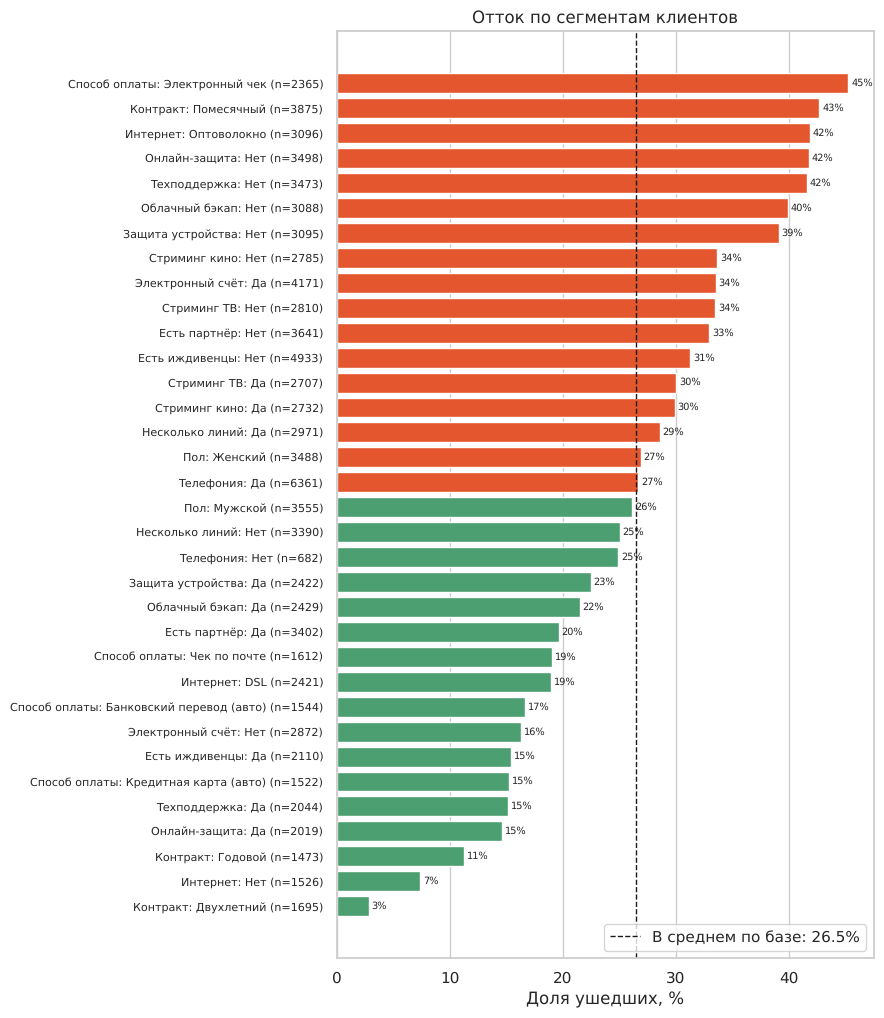

In [9]:
base = df["Отток"].mean() * 100
parts = []
for col in df.select_dtypes("category").columns:
    g = df.groupby(col, observed=True)["Отток"].agg(rate="mean", n="size")
    g = g.drop(index=["Нет интернета", "Нет телефонии"], errors="ignore")   # эти группы = «Интернет: Нет» / «Телефония: Нет», не повторяем 7 раз
    g.index = [f"{col}: {v} (n={n})" for v, n in zip(g.index, g["n"])]
    parts.append(g)
seg = pd.concat(parts).sort_values("rate")
seg["rate"] *= 100

fig, ax = plt.subplots(figsize=(9, 0.26 * len(seg) + 1.5))
ax.barh(seg.index, seg["rate"], color=np.where(seg["rate"] > base, palette["Ушёл"], palette["Остался"]))
ax.bar_label(ax.containers[0], fmt="%.0f%%", fontsize=7, padding=2)
ax.axvline(base, color="k", ls="--", lw=1, label=f"В среднем по базе: {base:.1f}%")
ax.set_xlabel("Доля ушедших, %"); ax.set_title("Отток по сегментам клиентов"); ax.legend(loc="lower right")
ax.tick_params(axis="y", labelsize=8); ax.grid(axis="y", visible=False)
plt.tight_layout()

**Числовые признаки — KDE (форма распределения) и boxplot (медиана, квартили, выбросы)** в одном рисунке.
У ушедших ярко выражен пик в первые месяцы `Стаж`; ушедшие чаще сидят на более дорогих тарифах.
`Всего оплачено` не рисуем: это почти `Стаж × Платёж в месяц`, новой информации график не даст (связь видна в матрице Phik ниже). Violin plot убран — он повторяет KDE и boxplot.

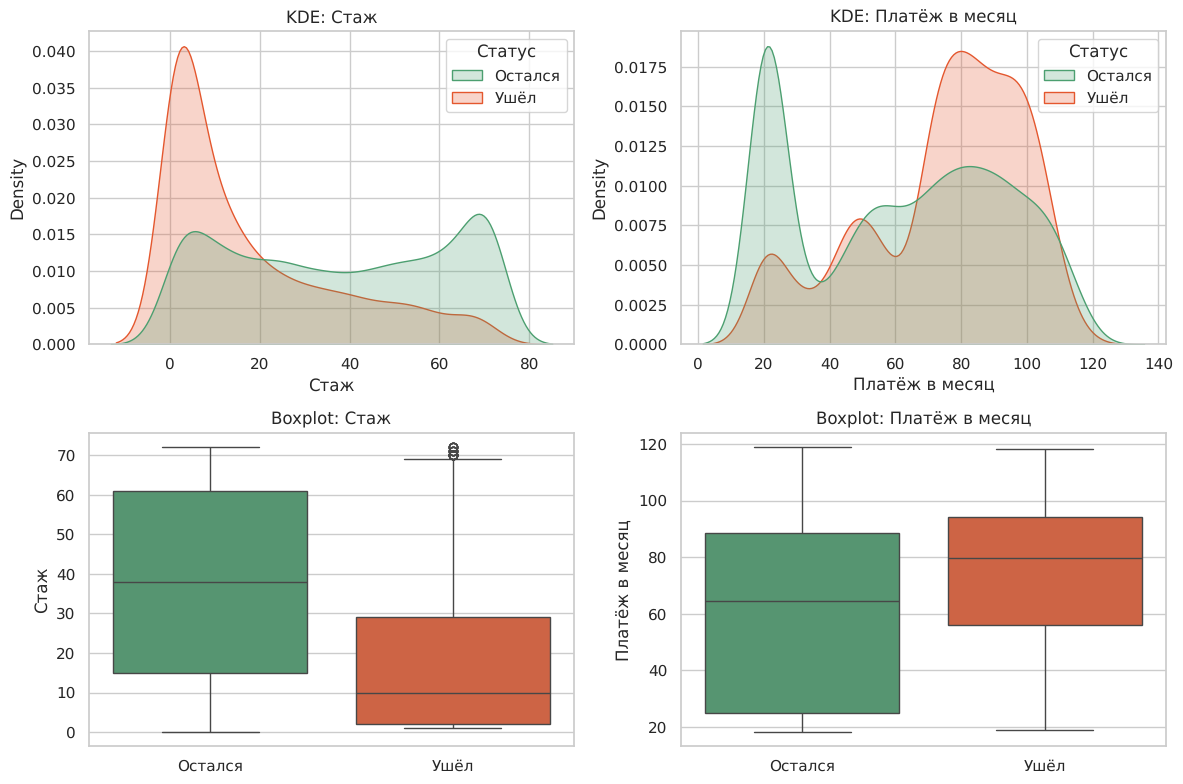

In [10]:
num_cols = ["Стаж", "Платёж в месяц"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for j, col in enumerate(num_cols):
    sns.kdeplot(data=df, x=col, hue=churn_lbl, fill=True, common_norm=False, palette=palette, ax=axes[0, j])
    axes[0, j].set_title(f"KDE: {col}")
    sns.boxplot(data=df, x=churn_lbl, y=col, hue=churn_lbl, palette=palette, legend=False, ax=axes[1, j])
    axes[1, j].set_title(f"Boxplot: {col}"); axes[1, j].set_xlabel("")
plt.tight_layout()

**Интерактивный scatter (Plotly)** — `Стаж` против `Платёж в месяц`, цвет по оттоку.
Наведите курсор на точку: видно контракт, интернет и способ оплаты клиента (удобно разбирать аномалии, например лояльного клиента с большим стажем, который всё же ушёл).

In [11]:
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "notebook_connected"   # файл ноутбука остаётся лёгким

fig = px.scatter(df.assign(Статус=churn_lbl), x="Стаж", y="Платёж в месяц", color="Статус",
                 color_discrete_map=palette, opacity=0.6,
                 hover_data=["Контракт", "Интернет", "Способ оплаты", "Всего оплачено"],
                 title="Стаж и ежемесячный платёж: кто уходит")
fig.show()

**Корреляции — коэффициент Фиката (Phik).** В отличие от Пирсона работает и с категориями, и с нелинейными связями.
Признаки отсортированы по силе связи с `Отток` (первая строка/столбец) — отдельная таблица рейтинга не нужна.

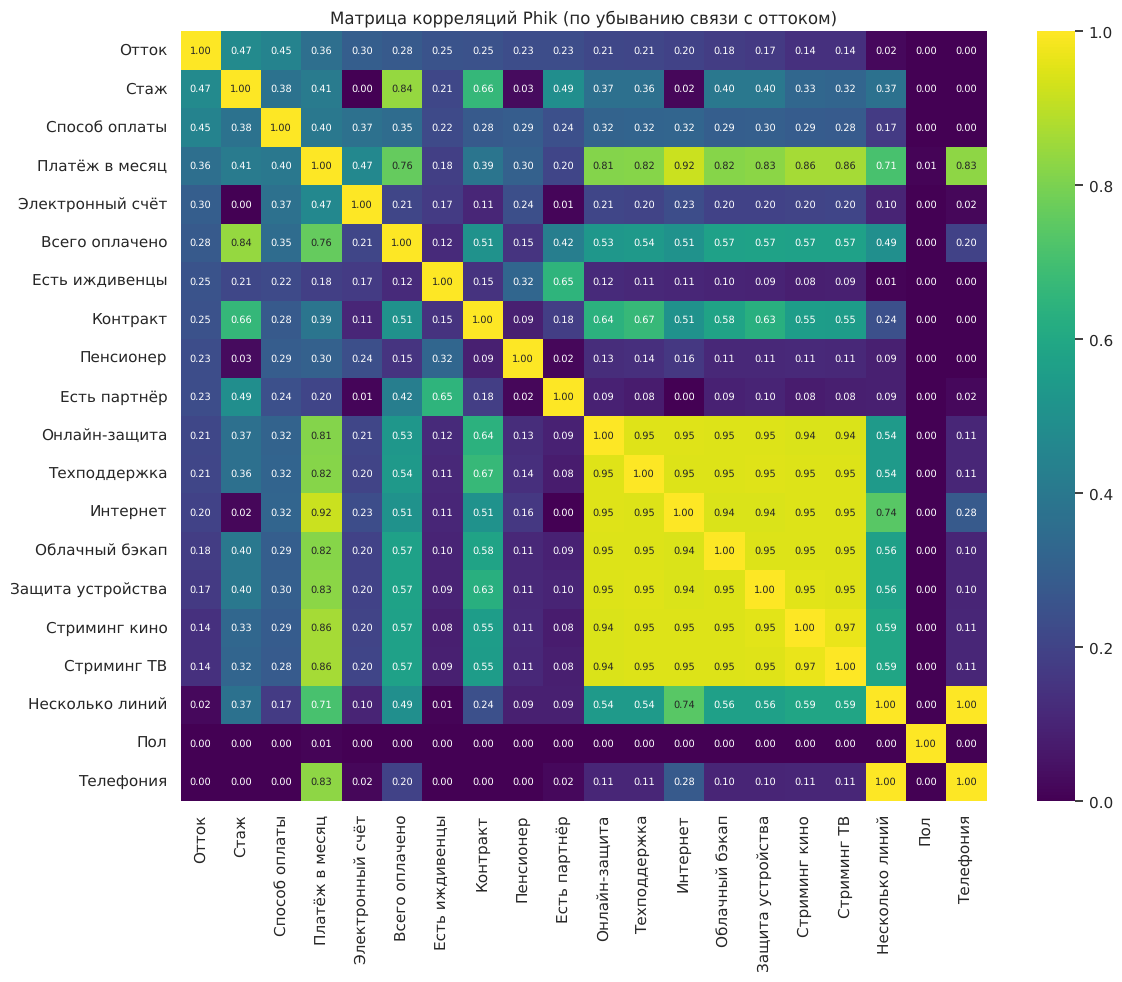

In [12]:
interval = ["Стаж", "Платёж в месяц", "Всего оплачено"]
phik_corr = df.phik_matrix(interval_cols=interval)
order = phik_corr["Отток"].sort_values(ascending=False).index          # Отток окажется первым (сам с собой = 1)
plt.figure(figsize=(13, 10))
sns.heatmap(phik_corr.loc[order, order], cmap="viridis", vmin=0, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Матрица корреляций Phik (по убыванию связи с оттоком)");

> **Выводы EDA:** по Phik сильнее всего с оттоком связаны `Стаж`, `Способ оплаты` и `Платёж в месяц`; заметна связь и с `Контракт`, `Электронный счёт`.
> `Пол` и `Телефония` не связаны с оттоком вообще. `Всего оплачено` сильно зависит от `Стаж` (≈ Стаж × Платёж в месяц).
> Phik показывает силу связи, но не направление — направление смотрим на графиках сегментов и распределений выше и в коэффициентах модели (раздел 5).

## 3. Подготовка признаков
Делим на train/test (с `stratify`, чтобы доля оттока была одинаковой), затем в одном `Pipeline`:
- числа → `StandardScaler`,
- категории → `OneHotEncoder`.

Преобразования внутри пайплайна учатся только на train → нет утечки данных.

In [13]:
X = df.drop(columns="Отток")
y = df["Отток"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

num_features = X.select_dtypes("number").columns.tolist()
cat_features = X.select_dtypes("category").columns.tolist()

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_features),
])
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (5634, 19) | Test: (1409, 19)


## 4. Базовые модели
Две простые и объяснимые модели:
1. **Логистическая регрессия** — линейная, коэффициенты легко читаются.
2. **Случайный лес** — нелинейная, ловит взаимодействия признаков.

`class_weight="balanced"` компенсирует дисбаланс классов.

In [14]:
models = {
    "Логистическая регрессия": LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE),
    "Случайный лес": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, max_depth=8,
                                           class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1),
}

fitted, rows = {}, []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    rows.append({"Модель": name,
                 "ROC-AUC": roc_auc_score(y_test, proba),
                 "Точность (Precision)": precision_score(y_test, pred),
                 "Полнота (Recall)": recall_score(y_test, pred),
                 "F1": f1_score(y_test, pred)})

results = pd.DataFrame(rows).set_index("Модель").round(3)
results

,ROC-AUC,Точность (Precision),Полнота (Recall),F1
Модель,,,,
Логистическая регрессия,0.842,0.504,0.783,0.614
Случайный лес,0.843,0.519,0.791,0.627


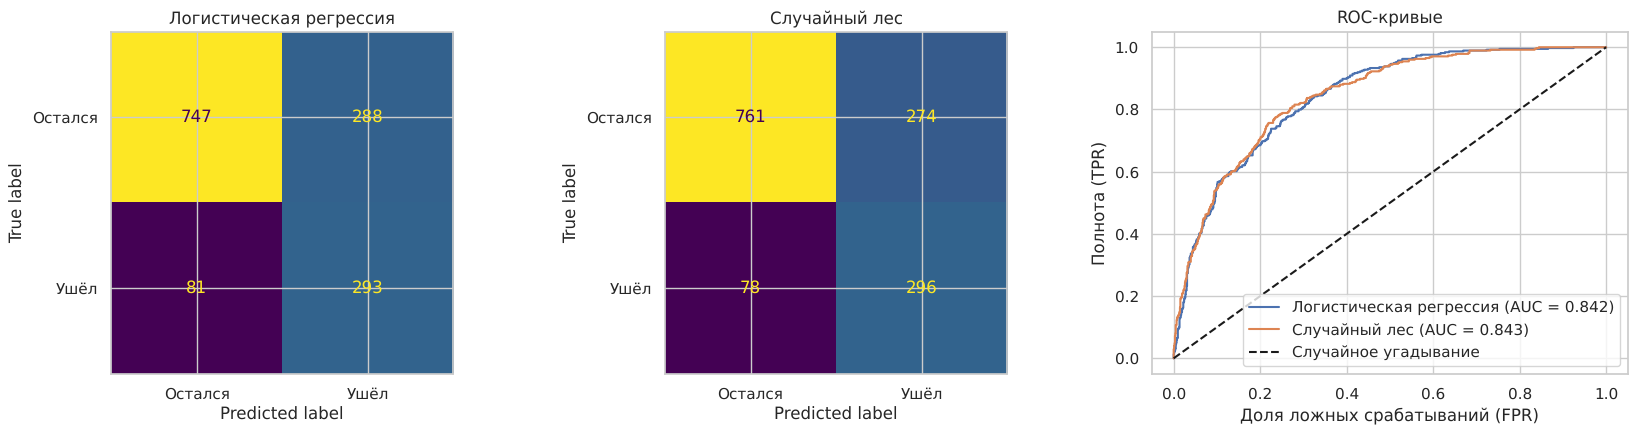

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, (name, pipe) in zip(axes[:2], fitted.items()):
    ConfusionMatrixDisplay.from_estimator(pipe, X_test, y_test, ax=ax, colorbar=False,
                                          display_labels=["Остался", "Ушёл"])
    ax.set_title(name)
ax = axes[2]
for name, pipe in fitted.items():
    proba_ = pipe.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, proba_)
    ax.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba_):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Случайное угадывание")
ax.set_xlabel("Доля ложных срабатываний (FPR)"); ax.set_ylabel("Полнота (TPR)")
ax.set_title("ROC-кривые"); ax.legend()
plt.tight_layout()

Слева — матрицы ошибок, справа — **ROC-кривые** двух моделей на одном графике: чем выше кривая над диагональю, тем лучше модель отделяет уходящих клиентов от остающихся.

Обе модели дают близкое качество (ROC-AUC ≈ 0.84) — для такого набора это типичный результат; простая логрегрессия не хуже леса, поэтому её можно использовать как основную из-за интерпретируемости.

## 5. Ключевые факторы риска ухода
### 5.1 Коэффициенты логистической регрессии
Положительный коэффициент → признак **повышает** вероятность оттока, отрицательный → **снижает**.
(Числа стандартизованы, поэтому их коэффициенты можно сравнивать между собой.)

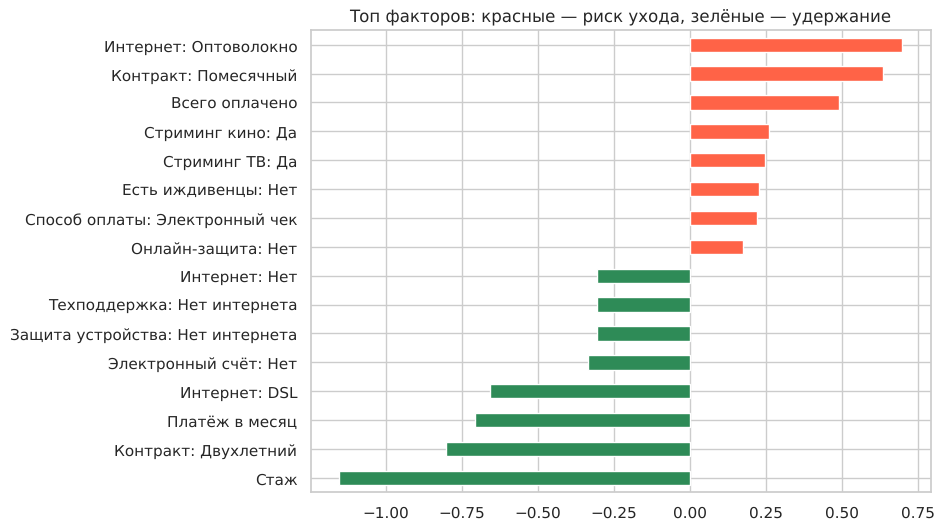

In [16]:
lr = fitted["Логистическая регрессия"]
names = lr.named_steps["prep"].get_feature_names_out()
names = [n.split("__", 1)[1].replace("_", ": ", 1) for n in names]   # убираем служебный префикс
coef = pd.Series(lr.named_steps["model"].coef_[0], index=names).sort_values()

top = pd.concat([coef.head(8), coef.tail(8)])
top.plot.barh(figsize=(8, 6), color=(top > 0).map({True: "tomato", False: "seagreen"}),
              title="Топ факторов: красные — риск ухода, зелёные — удержание");

### 5.2 Важность признаков: SHAP (логрегрессия) и permutation importance (случайный лес)
Обе метрики отвечают на один вопрос — «какие исходные признаки сильнее всего двигают прогноз», поэтому показываем их на одном графике, нормировав на 100%.
- **SHAP** — средний вклад признака в прогноз модели; вклады «Контракт: Помесячный», «Контракт: Двухлетний» и т.д. складываем в один признак «Контракт».
- **Permutation** — на сколько падает ROC-AUC на тесте, если перемешать признак.

Если обе модели ставят признак наверх — это надёжный фактор риска.

Background dataset has 5634 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=5634 when initializing the masker.


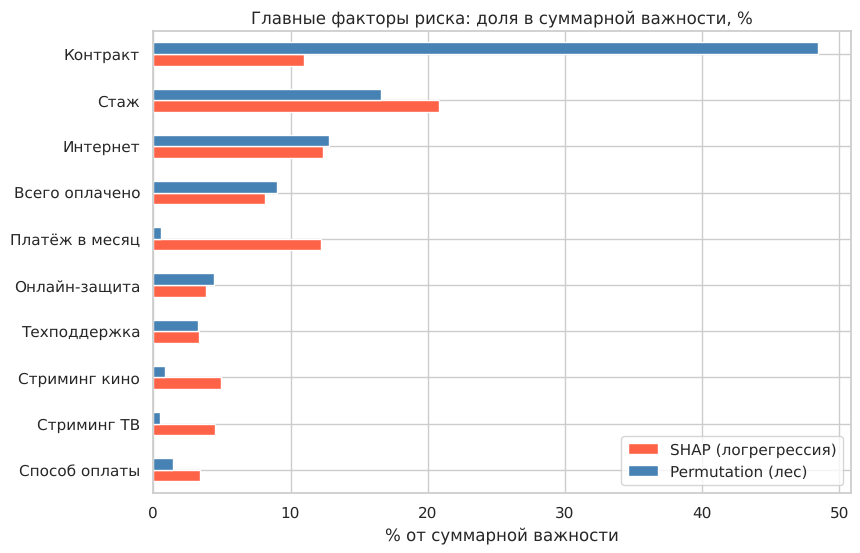

In [17]:
import shap

# --- SHAP для логистической регрессии, сгруппированный по исходным признакам ---
prep, lr_model = lr.named_steps["prep"], lr.named_steps["model"]
to_dense = lambda m: m.toarray() if hasattr(m, "toarray") else np.asarray(m)
X_train_t, X_test_t = to_dense(prep.transform(X_train)), to_dense(prep.transform(X_test))
explainer = shap.LinearExplainer(lr_model, X_train_t)
shap_df = pd.DataFrame(explainer.shap_values(X_test_t), columns=names)
original_feature = shap_df.columns.str.split(": ").str[0]
shap_imp = shap_df.T.groupby(original_feature).sum().T.abs().mean()

# --- permutation importance для случайного леса ---
perm = permutation_importance(fitted["Случайный лес"], X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_test.columns).clip(lower=0)

cmp_imp = pd.DataFrame({"SHAP (логрегрессия)": shap_imp / shap_imp.sum() * 100,
                        "Permutation (лес)": perm_imp / perm_imp.sum() * 100})
top10 = cmp_imp.mean(axis=1).sort_values().tail(10).index
cmp_imp.loc[top10].plot.barh(figsize=(9, 6), color=["tomato", "steelblue"],
                             title="Главные факторы риска: доля в суммарной важности, %")
plt.xlabel("% от суммарной важности");

### 5.4 Для бизнеса: клиенты в зоне риска
Уровень оттока по контрактам смотрите на графике сегментов в разделе 2.1. Список клиентов строим **только по тестовой выборке** (модель этих клиентов не видела), порог риска — 70%.
Так как модель обучена с `class_weight="balanced"`, вероятности завышены относительно реальной доли оттока (≈ 27%) — их стоит читать как ранжирование клиентов, а не как точный процент.

In [18]:
proba = fitted["Логистическая регрессия"].predict_proba(X_test)[:, 1]
risk = X_test[["Контракт", "Стаж", "Платёж в месяц"]].assign(**{"Вероятность оттока": proba.round(3),
                                                                  "Реально ушёл": y_test})
high_risk = risk[risk["Вероятность оттока"] >= 0.7].sort_values("Вероятность оттока", ascending=False)

print(f"Клиентов с риском ≥ 70%: {len(high_risk)} из {len(risk)}")
print(f"Из них реально ушло: {high_risk['Реально ушёл'].mean():.0%}")
high_risk.to_csv("high_risk_customers.csv")
high_risk.head(10)

Клиентов с риском ≥ 70%: 374 из 1409
Из них реально ушло: 60%


,Контракт,Стаж,Платёж в месяц,Вероятность оттока,Реально ушёл
customerID,,,,,
5178-LMXOP,Помесячный,1,95.099998,0.938,1
0295-PPHDO,Помесячный,1,95.449997,0.926,1
6861-XWTWQ,Помесячный,7,99.250000,0.926,1
8884-ADFVN,Помесячный,7,101.949997,0.922,1
1069-XAIEM,Помесячный,1,85.050003,0.920,1
1400-MMYXY,Помесячный,3,105.900002,0.920,1
2545-EBUPK,Помесячный,2,84.050003,0.920,0
9057-SIHCH,Помесячный,3,96.599998,0.919,1
6023-YEBUP,Помесячный,3,100.949997,0.919,1


### 5.5 Сохранение лучшей модели
Сохраняем весь пайплайн (предобработка + модель): его можно загрузить и сразу предсказывать на новых клиентах.

In [19]:
best_name = results["ROC-AUC"].idxmax()
joblib.dump(fitted[best_name], "best_churn_model.joblib")
print("Сохранена модель:", best_name)

Сохранена модель: Случайный лес


## 6. Выводы
**Качество:** ROC-AUC ≈ 0.84 на отложенной выборке; recall по классу «отток» ≈ 0.78 за счёт `class_weight="balanced"` (ценой более низкой precision).

**Факторы риска ухода:**
1. **Контракт «месяц в месяц»** — главный фактор; годовые и двухлетние контракты резко снижают отток.
2. **Малый срок обслуживания (Стаж)** — первые месяцы самые рискованные.
3. **Оптоволоконный интернет** — у DSL-абонентов отток ниже.
4. **Безбумажный биллинг** и рост суммарных платежей (`Всего оплачено`) при прочих равных.
5. **Отсутствие доп. услуг** («Техподдержка», «Онлайн-защита») — по важности признаков они заметны, клиенты с ними уходят реже.

*Примечание:* `Платёж в месяц` в линейной модели получает отрицательный коэффициент — он сильно коррелирует с типом интернета и допуслугами, поэтому в одиночку его читать нельзя (на графиках EDA высокий платёж связан с оттоком).

**Рекомендации бизнесу:** переводить клиентов на длинные контракты, давать бонусы новичкам в первые месяцы, предлагать пакет «Техподдержка»/«Онлайн-защита», проверить качество и цену оптоволоконных тарифов.

**Дальше (к итоговой защите):** подбор гиперпараметров (`GridSearchCV`), градиентный бустинг, подбор порога классификации под бизнес-метрику.